In [1]:
import torch

In [2]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

device

'cpu'

In [3]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

In [4]:
import pandas as pd
from pathlib import Path
import numpy as np

path = Path("../datasets/cta.csv")
df = pd.read_csv(path, parse_dates=["service_date"])
df.columns = ["date", "day_type", "bus", "rail", "total"] 
df = df.sort_values("date").set_index("date")
df = df.drop("total", axis=1)  
df = df.drop_duplicates()  


In [5]:
df['bus'] = df['bus'].values.map(lambda x: int(x.replace(',', '')))
df['rail'] = df['rail'].values.map(lambda x: int(x.replace(',', '')))


In [6]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 8947 entries, 2001-01-01 to 2025-06-30
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   day_type  8947 non-null   str  
 1   bus       8947 non-null   int64
 2   rail      8947 non-null   int64
dtypes: int64(2), str(1)
memory usage: 279.6 KB


In [7]:
df.head()

,day_type,bus,rail
date,,,
2001-01-01,U,297192,126455
2001-01-02,W,780827,501952
2001-01-03,W,824923,536432
2001-01-04,W,870021,550011
2001-01-05,W,890426,557917


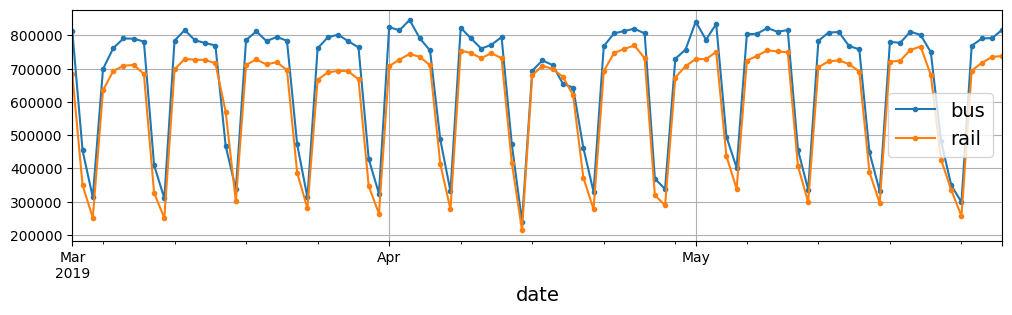

In [8]:
import matplotlib.pyplot as plt

df["2019-03":"2019-05"].plot(grid=True, marker=".", figsize=(12, 3))
plt.show()

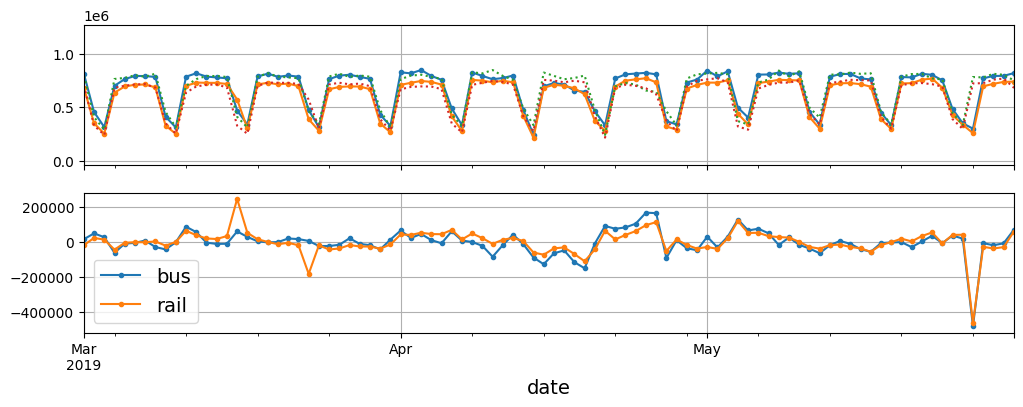

In [9]:
diff_7 = df[["bus", "rail"]].diff(7)["2019-03":"2019-05"]
fig, axs = plt.subplots(2, 1, sharex=True, figsize=(12, 4))
df.plot(ax=axs[0], legend=False, marker=".") # original timeseries
df.shift(7).plot(ax=axs[0], grid=True, legend=False,
linestyle=":") # lagged
diff_7.plot(ax=axs[1], grid=True, marker=".") # 7-day difference time series
plt.show()

In [10]:
list(df.loc["2019-05-25":"2019-05-28"].day_type)

['A', 'U', 'U', 'W']

In [11]:
diff_7.abs().mean()

bus     43915.608696
rail    42143.271739
dtype: float64

In [12]:
targets = df[['rail', 'bus']]['2019-03':'2019-05']
(diff_7 / targets).mean().abs()

bus     0.017776
rail    0.017551
dtype: float64

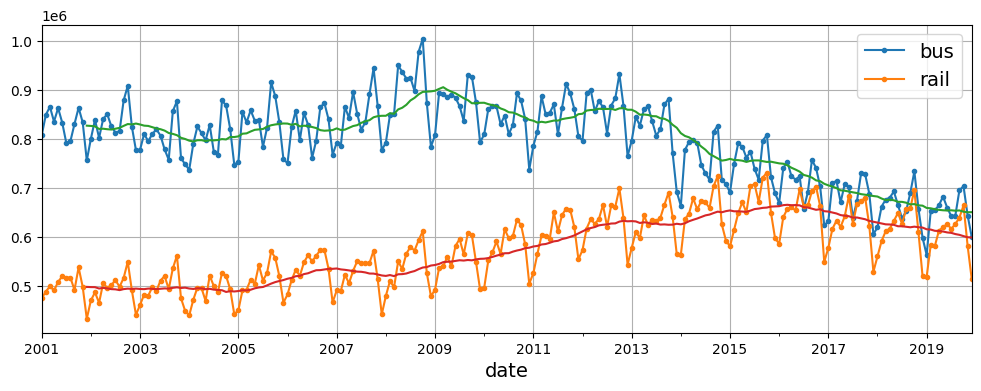

In [13]:
period = slice("2001", "2019")
df_monthly = df.select_dtypes(include='number').resample("ME").mean()
rolling_average_12_months = df_monthly.loc[period].rolling(window=12).mean()
fig, ax = plt.subplots(figsize=(12, 4))
df_monthly[period].plot(ax=ax, marker='.')
rolling_average_12_months.plot(ax=ax, grid=True, legend=False)
plt.show()

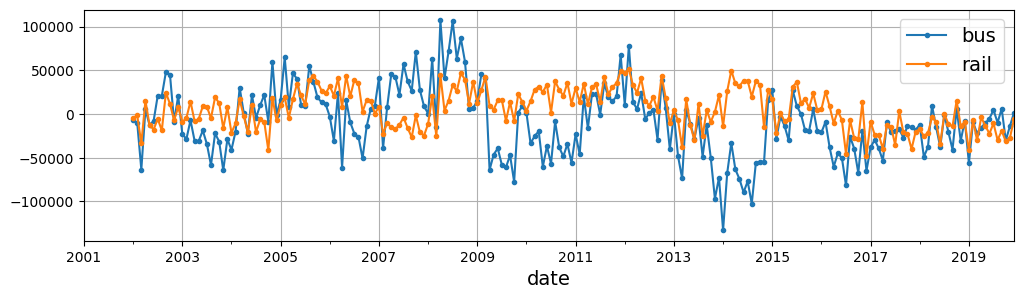

In [ ]:
df_monthly.diff(12)[period].plot(grid=True,marker='.', figsize=(12, 3))
plt.show()             


## Prepare the data for ML model

In [ ]:
class TimeSeriesDataset(torch.utils.data.Dataset):
    def __init__(self, series, window_length):
        super().__init__()
        self.series = series
        self.window_length = window_length

    def __len__(self):
        return len(self.series) - self.window_length

    def __getitem__(self, index):
        if index >= len(self):
            raise IndexError("Dataset is out of range")
        
        end = index + self.window_length
        window  = self.series[index : end]
        target = self.series[end]

        return window, target


my_series = torch.tensor([[0], [1], [2], [3], [4], [5]])
my_dataset = TimeSeriesDataset(my_series, window_length=2)
for window, target in my_dataset:
    print("Window:", window, " Target:", target)
my_series.shape

Window: tensor([[0],
        [1]])  Target: tensor([2])
Window: tensor([[1],
        [2]])  Target: tensor([3])
Window: tensor([[2],
        [3]])  Target: tensor([4])
Window: tensor([[3],
        [4]])  Target: tensor([5])


torch.Size([6, 1])

In [16]:
from torch.utils.data import DataLoader
torch.manual_seed(0)

my_loader = DataLoader(my_dataset, batch_size=2, shuffle=True)
for X, y in my_loader:
    print(f"X: {X}, y: {y}")

X: tensor([[[2],
         [3]],

        [[1],
         [2]]]), y: tensor([[4],
        [3]])
X: tensor([[[3],
         [4]],

        [[0],
         [1]]]), y: tensor([[5],
        [2]])


In [17]:
rail_train = torch.FloatTensor(df[["rail"]]["2016-01":"2018-12"].values / 1e6 )
rail_valid = torch.FloatTensor(df[["rail"]]["2019-01":"2019-05"].values / 1e6 )
rail_test = torch.FloatTensor(df[["rail"]]["2019-06":].values / 1e6 )

bus_train = torch.FloatTensor(df[["bus"]]["2016-01":"2018-12"].values / 1e6 )
bus_valid = torch.FloatTensor(df[["bus"]]["2019-01":"2019-05"].values / 1e6 )
bus_test = torch.FloatTensor(df[["bus"]]["2019-06":].values / 1e6 )

In [18]:
window_length = 56
batch_size = 32

# ----------------------------for rail---------------------

rail_train_set = TimeSeriesDataset(rail_train, window_length)
rail_train_loader = DataLoader(rail_train_set, batch_size)

rail_valid_set = TimeSeriesDataset(rail_valid, window_length)
rail_valid_loader = DataLoader(rail_valid_set, batch_size)

rail_test_set = TimeSeriesDataset(rail_test, window_length)
rail_test_loader = DataLoader(rail_test_set, batch_size)

# ----------------------------for bus---------------------

bus_train_set = TimeSeriesDataset(bus_train, window_length)
bus_train_loader = DataLoader(bus_train_set, batch_size)

bus_valid_set = TimeSeriesDataset(bus_valid, window_length)
bus_valid_loader = DataLoader(bus_valid_set, batch_size)

bus_test_set = TimeSeriesDataset(bus_test, window_length)
bus_test_loader = DataLoader(bus_test_set, batch_size)


In [19]:
import torchmetrics

def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            metric.update(y_pred, y_batch)
    return metric.compute()

def train(model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs, patience=10, factor=0.1):
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", patience=patience, factor=factor)
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(metric.compute().item())
        val_metric = evaluate_tm(model, valid_loader, metric).item()
        history["valid_metrics"].append(val_metric)
        scheduler.step(val_metric)
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.4f}, "
              f"valid metric: {history['valid_metrics'][-1]:.4f}")
    return history

In [20]:
import torch.nn as nn

torch.manual_seed(42)
model = nn.Sequential(nn.Flatten(), nn.Linear(window_length, 1)).to(device)
loss_fn = nn.HuberLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.003, momentum=0.9)
metric = torchmetrics.MeanAbsoluteError().to(device)

history = train(model, optimizer, loss_fn, metric, rail_train_loader, rail_valid_loader, n_epochs=20)

Epoch 1/20, train loss: 0.0167, train metric: 0.1487, valid metric: 0.1204
Epoch 2/20, train loss: 0.0104, train metric: 0.1126, valid metric: 0.0967
Epoch 3/20, train loss: 0.0081, train metric: 0.0944, valid metric: 0.0790
Epoch 4/20, train loss: 0.0069, train metric: 0.0833, valid metric: 0.0684
Epoch 5/20, train loss: 0.0062, train metric: 0.0763, valid metric: 0.0612
Epoch 6/20, train loss: 0.0058, train metric: 0.0715, valid metric: 0.0557
Epoch 7/20, train loss: 0.0055, train metric: 0.0681, valid metric: 0.0516
Epoch 8/20, train loss: 0.0053, train metric: 0.0655, valid metric: 0.0487
Epoch 9/20, train loss: 0.0051, train metric: 0.0635, valid metric: 0.0464
Epoch 10/20, train loss: 0.0049, train metric: 0.0619, valid metric: 0.0448
Epoch 11/20, train loss: 0.0048, train metric: 0.0607, valid metric: 0.0439
Epoch 12/20, train loss: 0.0047, train metric: 0.0596, valid metric: 0.0432
Epoch 13/20, train loss: 0.0046, train metric: 0.0588, valid metric: 0.0426
Epoch 14/20, train lo

In [21]:
evaluate_tm(model, rail_valid_loader, metric).item() * 1e6

41077.177971601486

In [22]:
class SimpleRnnModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.memory_cell = nn.Sequential(
            nn.Linear(input_size + hidden_size, hidden_size),
            nn.Tanh()
        )
        self.output = nn.Linear(hidden_size, output_size)

    def forward(self, X):
        batch_size, window_length, dimensionality = X.shape
        X_time_first = X.transpose(0, 1)
        H = torch.zeros(batch_size, self.hidden_size, device=X.device)
        for X_t in X_time_first:
            XH = torch.cat((X_t, H), dim=1)
            H = self.memory_cell(XH)
        return self.output(H)

torch.manual_seed(42)
model = SimpleRnnModel(input_size=1, hidden_size=32, output_size=1).to(device)

In [23]:
import torchmetrics 

def fit_and_evaluate(model, train_loader, valid_loader, lr, n_epochs=50,
                     patience=20, factor=0.1):
    loss_fn = nn.HuberLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.95)
    metric = torchmetrics.MeanAbsoluteError().to(device)
    history = train(model, optimizer, loss_fn, metric,
                    train_loader, valid_loader, n_epochs=n_epochs,
                    patience=patience, factor=factor)
    return min(history["valid_metrics"]) * 1e6

In [24]:
torch.manual_seed(42)
history = fit_and_evaluate(model,  train_loader=rail_train_loader, valid_loader=rail_valid_loader, lr=0.05)

Epoch 1/50, train loss: 0.0619, train metric: 0.2909, valid metric: 0.2138
Epoch 2/50, train loss: 0.0202, train metric: 0.1654, valid metric: 0.1174
Epoch 3/50, train loss: 0.0133, train metric: 0.1420, valid metric: 0.1236
Epoch 4/50, train loss: 0.0112, train metric: 0.1258, valid metric: 0.1073
Epoch 5/50, train loss: 0.0079, train metric: 0.0983, valid metric: 0.0926
Epoch 6/50, train loss: 0.0062, train metric: 0.0825, valid metric: 0.0761
Epoch 7/50, train loss: 0.0056, train metric: 0.0776, valid metric: 0.0725
Epoch 8/50, train loss: 0.0052, train metric: 0.0736, valid metric: 0.0687
Epoch 9/50, train loss: 0.0049, train metric: 0.0709, valid metric: 0.0663
Epoch 10/50, train loss: 0.0047, train metric: 0.0688, valid metric: 0.0643
Epoch 11/50, train loss: 0.0046, train metric: 0.0674, valid metric: 0.0633
Epoch 12/50, train loss: 0.0044, train metric: 0.0659, valid metric: 0.0620
Epoch 13/50, train loss: 0.0042, train metric: 0.0642, valid metric: 0.0622
Epoch 14/50, train lo

In [25]:
history

32890.97920060158

In [26]:
class SimpleRnnModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True)
        self.output = nn.Linear(hidden_size, output_size)

    def forward(self, X):
        outputs, last_state = self.rnn(X)
        return self.output(outputs[:, -1])


In [27]:
univar_model = SimpleRnnModel(input_size=1, hidden_size=32, output_size=1).to(device)
torch.manual_seed(42)
history = fit_and_evaluate(model=univar_model,  train_loader=rail_train_loader, valid_loader=rail_valid_loader, lr=0.1)

Epoch 1/50, train loss: 0.0311, train metric: 0.1967, valid metric: 0.1606
Epoch 2/50, train loss: 0.0223, train metric: 0.1696, valid metric: 0.1798
Epoch 3/50, train loss: 0.0107, train metric: 0.1118, valid metric: 0.0871
Epoch 4/50, train loss: 0.0063, train metric: 0.0829, valid metric: 0.0721
Epoch 5/50, train loss: 0.0054, train metric: 0.0738, valid metric: 0.0694
Epoch 6/50, train loss: 0.0050, train metric: 0.0699, valid metric: 0.0591
Epoch 7/50, train loss: 0.0049, train metric: 0.0681, valid metric: 0.0585
Epoch 8/50, train loss: 0.0045, train metric: 0.0652, valid metric: 0.0573
Epoch 9/50, train loss: 0.0041, train metric: 0.0611, valid metric: 0.0615
Epoch 10/50, train loss: 0.0038, train metric: 0.0561, valid metric: 0.0512
Epoch 11/50, train loss: 0.0036, train metric: 0.0554, valid metric: 0.0597
Epoch 12/50, train loss: 0.0035, train metric: 0.0533, valid metric: 0.0546
Epoch 13/50, train loss: 0.0034, train metric: 0.0526, valid metric: 0.0520
Epoch 14/50, train lo

In [28]:
history

30019.991099834442

# Deep RNNs

In [29]:
class DeepRNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, num_layers):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)
        self.output = nn.Linear(hidden_size, output_size)

    def forward(self, X):
        outputs, last_state = self.rnn(X)
        return self.output(outputs[:, -1])

model = DeepRNN(input_size=1, hidden_size=32, output_size=1, num_layers=3).to(device)
torch.manual_seed(42)
fit_and_evaluate(model,  train_loader=rail_train_loader, valid_loader=rail_valid_loader, lr=0.1)

Epoch 1/50, train loss: 0.0471, train metric: 0.2485, valid metric: 0.1396
Epoch 2/50, train loss: 0.0252, train metric: 0.1854, valid metric: 0.1266
Epoch 3/50, train loss: 0.0152, train metric: 0.1393, valid metric: 0.1495
Epoch 4/50, train loss: 0.0073, train metric: 0.0870, valid metric: 0.0875
Epoch 5/50, train loss: 0.0062, train metric: 0.0793, valid metric: 0.0711
Epoch 6/50, train loss: 0.0058, train metric: 0.0740, valid metric: 0.0621
Epoch 7/50, train loss: 0.0055, train metric: 0.0711, valid metric: 0.0604
Epoch 8/50, train loss: 0.0052, train metric: 0.0683, valid metric: 0.0693
Epoch 9/50, train loss: 0.0049, train metric: 0.0665, valid metric: 0.0701
Epoch 10/50, train loss: 0.0051, train metric: 0.0710, valid metric: 0.0702
Epoch 11/50, train loss: 0.0044, train metric: 0.0637, valid metric: 0.0583
Epoch 12/50, train loss: 0.0044, train metric: 0.0631, valid metric: 0.0589
Epoch 13/50, train loss: 0.0041, train metric: 0.0612, valid metric: 0.0510
Epoch 14/50, train lo

31336.9520008564

In [30]:
df.columns

Index(['day_type', 'bus', 'rail'], dtype='str')

In [31]:
df_mulvar = df[['bus', 'rail']] / 1e6
df_mulvar['next_day_type'] = df['day_type'].shift(-1)
df_mulvar = pd.get_dummies(df_mulvar, dtype=float)


In [32]:
mulvar_train = torch.FloatTensor(df_mulvar["2016-01":"2018-12"].values)
mulvar_valid = torch.FloatTensor(df_mulvar["2019-01":"2019-05"].values)
mulvar_test = torch.FloatTensor(df_mulvar["2019-06":].values)

In [33]:
class MulvarTimeSeriesDataset(TimeSeriesDataset):
    def __getitem__(self, idx):
        window, target = super().__getitem__(idx)
        return window, target[:1]

In [34]:
window_length = 56
mulvar_train_set = MulvarTimeSeriesDataset(mulvar_train, window_length)
mulvar_train_loader = DataLoader(mulvar_train_set, batch_size=32, shuffle=True)
mulvar_valid_set = MulvarTimeSeriesDataset(mulvar_valid, window_length)
mulvar_valid_loader = DataLoader(mulvar_valid_set, batch_size=32)
mulvar_test_set = MulvarTimeSeriesDataset(mulvar_test, window_length)
mulvar_test_loader = DataLoader(mulvar_test_set, batch_size=32)

In [35]:
torch.manual_seed(43)
mulvar_model = SimpleRnnModel(input_size=5, hidden_size=32, output_size=1).to(device)
fit_and_evaluate(mulvar_model, mulvar_train_loader,mulvar_valid_loader, lr=0.05, n_epochs=50)

Epoch 1/50, train loss: 0.0562, train metric: 0.2763, valid metric: 0.0677
Epoch 2/50, train loss: 0.0091, train metric: 0.1105, valid metric: 0.0872
Epoch 3/50, train loss: 0.0036, train metric: 0.0651, valid metric: 0.0480
Epoch 4/50, train loss: 0.0023, train metric: 0.0487, valid metric: 0.0272
Epoch 5/50, train loss: 0.0021, train metric: 0.0454, valid metric: 0.0400
Epoch 6/50, train loss: 0.0019, train metric: 0.0444, valid metric: 0.0308
Epoch 7/50, train loss: 0.0019, train metric: 0.0451, valid metric: 0.0394
Epoch 8/50, train loss: 0.0018, train metric: 0.0424, valid metric: 0.0258
Epoch 9/50, train loss: 0.0016, train metric: 0.0408, valid metric: 0.0330
Epoch 10/50, train loss: 0.0016, train metric: 0.0410, valid metric: 0.0260
Epoch 11/50, train loss: 0.0014, train metric: 0.0387, valid metric: 0.0247
Epoch 12/50, train loss: 0.0014, train metric: 0.0383, valid metric: 0.0259
Epoch 13/50, train loss: 0.0015, train metric: 0.0386, valid metric: 0.0296
Epoch 14/50, train lo

24729.26490008831

In [36]:
class MultaskTimeSeriesDataset(TimeSeriesDataset):
    def __getitem__(self, idx):
        window, target =  super().__getitem__(idx)
        return window, target[:2]

window_length = 56
multask_train_set = MultaskTimeSeriesDataset(mulvar_train, window_length)
multask_train_loader = DataLoader(multask_train_set, batch_size=32, shuffle=True)
multask_valid_set = MultaskTimeSeriesDataset(mulvar_valid, window_length)
multask_valid_loader = DataLoader(multask_valid_set, batch_size=32)
multask_test_set = MultaskTimeSeriesDataset(mulvar_test, window_length)
multask_test_loader = DataLoader(multask_test_set, batch_size=32)

torch.manual_seed(42)
multask_model = SimpleRnnModel(input_size=5, hidden_size=32, output_size=2)
multask_model = multask_model.to(device)
fit_and_evaluate(multask_model, multask_train_loader, multask_valid_loader, lr=0.03, n_epochs=50)

Epoch 1/50, train loss: 0.0634, train metric: 0.2883, valid metric: 0.1232
Epoch 2/50, train loss: 0.0094, train metric: 0.1098, valid metric: 0.0712
Epoch 3/50, train loss: 0.0035, train metric: 0.0630, valid metric: 0.0341
Epoch 4/50, train loss: 0.0022, train metric: 0.0469, valid metric: 0.0358
Epoch 5/50, train loss: 0.0020, train metric: 0.0427, valid metric: 0.0311
Epoch 6/50, train loss: 0.0019, train metric: 0.0430, valid metric: 0.0385
Epoch 7/50, train loss: 0.0018, train metric: 0.0417, valid metric: 0.0389
Epoch 8/50, train loss: 0.0018, train metric: 0.0414, valid metric: 0.0318
Epoch 9/50, train loss: 0.0017, train metric: 0.0398, valid metric: 0.0320
Epoch 10/50, train loss: 0.0016, train metric: 0.0396, valid metric: 0.0346
Epoch 11/50, train loss: 0.0016, train metric: 0.0391, valid metric: 0.0330
Epoch 12/50, train loss: 0.0015, train metric: 0.0386, valid metric: 0.0322
Epoch 13/50, train loss: 0.0015, train metric: 0.0381, valid metric: 0.0310
Epoch 14/50, train lo

25160.253047943115

In [37]:
mulvar_model.eval()
Y_pred_valid = [multask_model(X.to(device)) for X, _ in multask_valid_loader]
Y_pred_valid = torch.cat(Y_pred_valid, dim=0)
Y_valid = torch.cat([Y.to(device) for _, Y in multask_valid_loader], dim=0)
for idx, name in enumerate(['rail', 'bus']):
    mae = (Y_pred_valid[:, idx] - Y_valid[:, idx]).abs().mean()
    print(name, int(mae * 1e6))

rail 25677
bus 25733


In [38]:
univar_model.eval()
n_steps = 14
with torch.no_grad():
    X = rail_valid[:window_length].unsqueeze(dim=0).to(device)
    for step_ahead in range(n_steps):
        y_pred_one = univar_model(X)
        X = torch.cat([X, y_pred_one.unsqueeze(dim=1)], dim=1)

    Y_pred = X[0, -n_steps:, 0]

In [39]:
Y_pred

tensor([0.7196, 0.7145, 0.7215, 0.7108, 0.3939, 0.2997, 0.6828, 0.7307, 0.7232,
        0.7292, 0.7228, 0.4105, 0.3154, 0.6963])

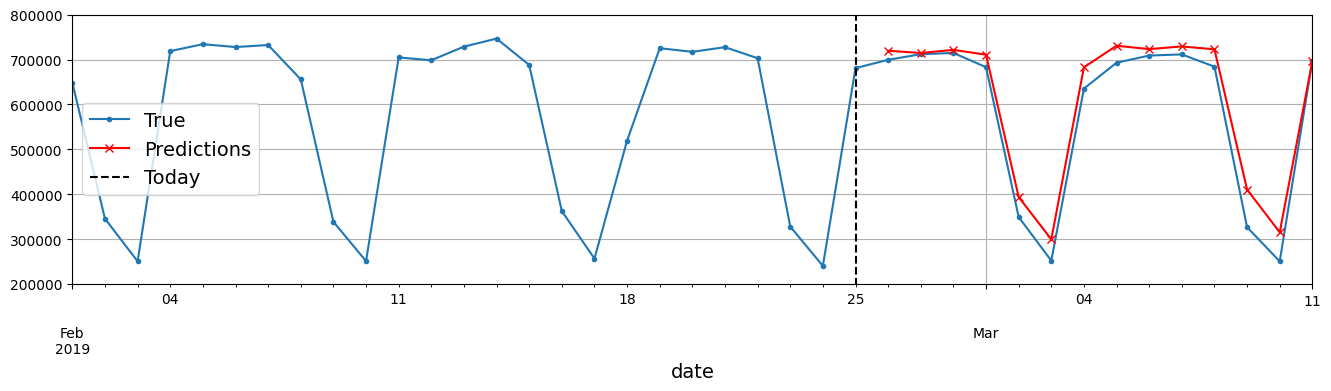

In [40]:
# extra code – generates Figure 13–11

# The forecasts start on 2019-02-26, as it is the 57th day of 2019, and they end
# on 2019-03-11. That's 14 days in total.
Y_pred_s = pd.Series(Y_pred.cpu() * 1e6,
                     index=pd.date_range("2019-02-26", "2019-03-11"))
fig, ax = plt.subplots(figsize=(16, 3.5))
df["2019-02-01":"2019-03-11"]["rail"].plot(label="True", marker=".", ax=ax)
Y_pred_s.plot(label="Predictions", grid=True, marker="x", color="r", ax=ax)
ax.vlines("2019-02-25", 0, 1e6, color="k", linestyle="--", label="Today")
ax.set_ylim([200_000, 800_000])
plt.legend(loc="center left")

plt.show()

In [41]:
train = torch.rand(1000, 1)
valid = torch.rand(200, 1)

train_dataset = TimeSeriesDataset(train, window_length=56)
valid_dataset = TimeSeriesDataset(valid, window_length=56)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True) 
valid_loader = DataLoader(valid_dataset, batch_size=32, shuffle=True) 


In [42]:
torch.manual_seed(123)
univar_model = SimpleRnnModel(1, 32, 1)
# fit_and_evaluate(univar_model,train_loader, valid_loader, lr=0.05, n_epochs=20)
for x_batch, y_batch in train_loader:
    # univar_model(x_batch)
    print(x_batch.shape)
    y_pred = univar_model(x_batch)
    print(y_pred.shape)
    break

torch.Size([32, 56, 1])
torch.Size([32, 1])


In [1]:
class PytorchRnnModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.rnn = nn.RNN(input_size,  hidden_size, batch_first=True)
        self.output = nn.Linear(hidden_size, output_size)

    def forward(self, X):
        outputs, last_state = self.rnn(X)
        return self.output(outputs[:, -1])

torch.manual_seed(123)
univar_model = PytorchRnnModel(1, 32, 1)
# fit_and_evaluate(univar_model,train_loader, valid_loader, lr=0.05, n_epochs=20)
for x_batch, y_batch in train_loader:
    # univar_model(x_batch)
    print(x_batch.shape)
    y_pred = univar_model(x_batch)
    print(y_pred.shape)
    break

KeyboardInterrupt: 

In [44]:
class DeepRnnModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, n_layers=5):
        super().__init__()
        self.rnn = nn.RNN(input_size,  hidden_size,num_layers=n_layers,  batch_first=True)
        self.output = nn.Linear(hidden_size, output_size)

    def forward(self, X):
        outputs, last_state = self.rnn(X)
        return self.output(outputs[:, -1])

torch.manual_seed(123)
univar_model = PytorchRnnModel(input_size=1,hidden_size=32,output_size=1)
# fit_and_evaluate(univar_model,train_loader, valid_loader, lr=0.05, n_epochs=20)
for x_batch, y_batch in train_loader:
    # univar_model(x_batch)
    print(x_batch.shape)
    y_pred = univar_model(x_batch)
    print(y_pred.shape)
    break

torch.Size([32, 56, 1])
torch.Size([32, 1])


In [45]:
# *****************************
# Forcasting the Multivariate Timeseries data
# *****************************

In [46]:
class MulvarTimeSeriesDataset(TimeSeriesDataset):
    def __getitem__(self, idx):
        window, target = super().__getitem__(idx)
        return window, target[:1]

In [47]:
mul_train = torch.rand(1000, 5)
mul_valid = torch.rand(200, 5)

mul_train_dataset = MulvarTimeSeriesDataset(mul_train, window_length=56)
mul_valid_dataset = MulvarTimeSeriesDataset(mul_valid, window_length=56)

mul_train_loader = DataLoader(mul_train_dataset, batch_size=32, shuffle=True) 
mul_valid_loader = DataLoader(mul_valid_dataset, batch_size=32, shuffle=True) 

In [48]:
mulvar = SimpleRnnModel(input_size=5, hidden_size=32, output_size=1)
for x_batch, y_batch in mul_train_loader:
    # univar_model(x_batch)
    print(x_batch.shape)
    y_pred = mulvar(x_batch)
    print(y_pred.shape) 
    break

# train the model here

torch.Size([32, 56, 5])
torch.Size([32, 1])


In [49]:
# *****************************
# Forcasting the Serveral Time Steps Ahead
# *****************************

In [50]:
# Option 1: predicating one by one then adding that upto when it reaches to 14
n_steps = 14
univar_model.eval()
with torch.no_grad():
    X = valid[:56].unsqueeze(dim=0)
    for step_ahead in range(n_steps):
        y_pred_one = univar_model(X)
        X = torch.cat([X, y_pred_one.unsqueeze(dim=0)], dim=1)
    
    Y_pred = X[0, -n_steps:, 0]

In [51]:
# Option 2: Predict 14 days in one shot
class ForecastAheadDataset(TimeSeriesDataset):
    def __len__(self):
        return len(self.series) - self.window_length - 14 + 1

    def __getitem__(self, idx):
        end = idx + self.window_length  # 1st index after window
        window = self.series[idx : end]
        target = self.series[end : end + 14, 0]  # 0 = rail ridership
        return window, target



In [52]:
ahead_train_set = ForecastAheadDataset(mul_train, window_length=56)
ahead_train_dataloader = DataLoader(ahead_train_set, batch_size=32, shuffle=True)
ahead_valid_set = ForecastAheadDataset(mul_valid,window_length=56)
ahead_valid_dataloader = DataLoader(ahead_valid_set, batch_size=32, shuffle=True)\

ahead_model = SimpleRnnModel(input_size=5, hidden_size=32, output_size=14)

for x_batch, y_batch in mul_train_loader:
    # univar_model(x_batch)
    print(x_batch.shape)
    y_pred = ahead_model(x_batch)
    print(y_pred.shape) 
    break


torch.Size([32, 56, 5])
torch.Size([32, 14])


In [53]:
ahead_model.eval()
with torch.no_grad():
    window = mul_valid[:56]  # shape [56, 5]
    X = window.unsqueeze(dim=0)            # shape [1, 56, 5]
    Y_pred = ahead_model(X.to(device))     # shape [1, 14]

In [54]:
# *****************************
# LSTM
# *****************************

In [55]:
class LstmModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.rnn = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.output = nn.Linear(hidden_size, output_size)

    def forward(self, X):
        outputs, last_state = self.rnn(X)
        return self.output(outputs[:, -1])

In [56]:
    
lstm_m = LstmModel(input_size=5, hidden_size=32, output_size=14)
for x_batch, y_batch in mul_train_loader:
    # univar_model(x_batch)
    print(x_batch.shape)
    y_pred = lstm_m(x_batch)
    print(y_pred.shape) 
    break
   

torch.Size([32, 56, 5])
torch.Size([32, 14])


In [57]:
class LstmModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.memory_cell = nn.LSTMCell(input_size, hidden_size)
        self.output = nn.Linear(hidden_size, output_size)

    def forward(self, X):
        batch, window_length, dimensionality = X.shape

        X_first_time = X.transpose(0, 1)
        H = torch.zeros(batch, self.hidden_size)
        C = torch.zeros(batch, self.hidden_size)

        for X_t in X_first_time:
            H, C = self.memory_cell(X_t, (H, C))
            
        return self.output(H)


In [58]:
lstm_m = LstmModel(input_size=5, hidden_size=32, output_size=14)
for x_batch, y_batch in mul_train_loader:
    # univar_model(x_batch)
    print(x_batch.shape)
    y_pred = lstm_m(x_batch)
    print(y_pred.shape) 
    break

torch.Size([32, 56, 5])
torch.Size([32, 14])


In [59]:
# *****************************
# GRU
# *****************************

In [60]:
class GRUModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.rnn = nn.GRU(input_size, hidden_size, batch_first=True)
        self.output = nn.Linear(hidden_size, output_size)

    def forward(self, X):
        outputs, last_state = self.rnn(X)
        return self.output(outputs[:, -1])

lstm_m = GRUModel(input_size=5, hidden_size=32, output_size=14)
for x_batch, y_batch in mul_train_loader:
    # univar_model(x_batch)
    print(x_batch.shape)
    y_pred = lstm_m(x_batch)
    print(y_pred.shape) 
    break

torch.Size([32, 56, 5])
torch.Size([32, 14])
